# Customer Segmentation & Rule-Based Churn-Risk Score
**Dataset:** synthetic customer churn sample (15 customers). Findings are illustrative, not real-world insights.

**Goal:** move from descriptive analytics to an explainable prioritisation model: (1) choose features, (2) define segments, (3) build a transparent, reproducible churn-risk score and test its edge cases.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("customer_churn_sample.csv")
df.columns = df.columns.str.strip().str.lower()
df["churned"] = df["churn"].map({"Yes": 1, "No": 0})
print(df.shape, "| missing values:", int(df.isna().sum().sum()))
df.head()

(15, 12) | missing values: 0


,customerid,gender,age,tenuremonths,subscriptiontype,monthlycharges,totalcharges,contracttype,supporttickets,paymentmethod,churn,churned
0,CUST-1001,Female,34,12,Basic,49.99,599.88,Month-to-Month,3,Credit Card,Yes,1
1,CUST-1002,Male,45,24,Pro,79.99,1919.76,One Year,1,Bank Transfer,No,0
2,CUST-1003,Female,29,6,Basic,49.99,299.94,Month-to-Month,5,UPI,Yes,1
3,CUST-1004,Male,52,36,Enterprise,149.99,5399.64,Two Year,0,Credit Card,No,0
4,CUST-1005,Female,41,8,Pro,79.99,639.92,Month-to-Month,4,Debit Card,Yes,1


## 1. Feature selection

| Feature | Used? | Why |
|---|---|---|
| `contracttype` | **Yes (score)** | Contract length is the main account-level lever on how easily a customer can leave |
| `tenuremonths` | **Yes (score)** | Lifecycle stage: newer customers have less switching cost and less habit |
| `supporttickets` | **Yes (score)** | Behavioural signal of friction or dissatisfaction |
| `monthlycharges` / `subscriptiontype` | **Yes (segments only)** | Measures customer value, used to prioritise who to save first, not to predict churn |
| `totalcharges` | No | Exactly tenure x monthly charges in this data, so it adds nothing new |
| `paymentmethod` | No | Groups of 2-4 customers: any rule would be noise |
| `gender`, `age` | No | Not behavioural, and using demographics to rank customers invites unfair treatment |
| `churn` | **Never used to build the score** | It is the outcome. It is only used afterwards to check the score |
| `customerid` | No | Identifier only |

## 2. Churn-risk score (0-100, rule-based)

Points are additive and every point has a plain-English reason:

| Rule | Points |
|---|---|
| Contract: Month-to-Month / One Year / Two Year | 40 / 15 / 0 |
| Tenure: 12 months or less / 13-24 months / over 24 months | 30 / 15 / 0 |
| Support tickets: 3 or more / 1-2 / none | 30 / 10 / 0 |

**Tiers:** High risk = 60 or more, Medium = 30-59, Low = below 30.

In [2]:
CONTRACT_PTS = {"Month-to-Month": 40, "One Year": 15, "Two Year": 0}
HIGH_CUTOFF, MED_CUTOFF = 60, 30

def risk_score(contract, tenure_months, tickets, tenure_cut=12):
    """Return a 0-100 churn-risk score. Raises ValueError on invalid input."""
    if contract not in CONTRACT_PTS:
        raise ValueError(f"unknown contract type: {contract!r}")
    if tenure_months is None or pd.isna(tenure_months) or tenure_months < 0:
        raise ValueError(f"invalid tenure: {tenure_months!r}")
    if tickets is None or pd.isna(tickets) or tickets < 0:
        raise ValueError(f"invalid ticket count: {tickets!r}")
    pts = CONTRACT_PTS[contract]
    pts += 30 if tenure_months <= tenure_cut else (15 if tenure_months <= 24 else 0)
    pts += 30 if tickets >= 3 else (10 if tickets >= 1 else 0)
    return pts

def risk_tier(score, high=HIGH_CUTOFF, med=MED_CUTOFF):
    return "High" if score >= high else ("Medium" if score >= med else "Low")

df["risk_score"] = [risk_score(c, t, k) for c, t, k in zip(df.contracttype, df.tenuremonths, df.supporttickets)]
df["risk_tier"] = df.risk_score.map(risk_tier)
df[["customerid", "contracttype", "tenuremonths", "supporttickets", "risk_score", "risk_tier", "churned"]].sort_values("risk_score", ascending=False)

,customerid,contracttype,tenuremonths,supporttickets,risk_score,risk_tier,churned
0,CUST-1001,Month-to-Month,12,3,100,High,1
2,CUST-1003,Month-to-Month,6,5,100,High,1
4,CUST-1005,Month-to-Month,8,4,100,High,1
6,CUST-1007,Month-to-Month,3,6,100,High,1
9,CUST-1010,Month-to-Month,4,4,100,High,1
13,CUST-1014,Month-to-Month,2,5,100,High,1
11,CUST-1012,Month-to-Month,14,3,85,High,1
12,CUST-1013,One Year,22,1,40,Medium,0
5,CUST-1006,One Year,18,2,40,Medium,0
1,CUST-1002,One Year,24,1,40,Medium,0


## 3. Validation: edge cases and boundaries

In [3]:
# Boundary and edge-case tests. Each row: (inputs, expected score)
tests = [
    (("Month-to-Month", 12, 3), 100),   # exactly on the 12-month and 3-ticket boundaries
    (("Month-to-Month", 13, 2), 65),    # one month / one ticket past the boundaries
    (("Month-to-Month", 60, 0), 40),    # long-tenure month-to-month with no tickets: Medium, not High
    (("Two Year", 1, 8), 60),           # brand-new two-year customer with many tickets: still High
    (("Two Year", 48, 0), 0),           # safest possible customer
    (("One Year", 24, 1), 40),          # exactly on the 24-month boundary
    (("One Year", 25, 0), 15),          # just past it
    (("Month-to-Month", 0, 0), 70),     # zero tenure is valid (just signed up)
]
for args, expected in tests:
    got = risk_score(*args)
    assert got == expected, (args, got, expected)
    print(f"OK {args} -> {got} ({risk_tier(got)})")

# Invalid inputs must fail loudly rather than return a misleading score
bad = [("Weekly", 5, 1), ("One Year", -1, 0), ("One Year", 5, -2), ("One Year", None, 0), ("One Year", float("nan"), 1)]
for args in bad:
    try:
        risk_score(*args); raise SystemExit(f"should have failed: {args}")
    except ValueError as e:
        print("Rejected:", args, "->", e)

assert df.risk_score.between(0, 100).all()
print("\nAll edge-case checks passed. Scores are deterministic: same inputs always give the same score.")

OK ('Month-to-Month', 12, 3) -> 100 (High)
OK ('Month-to-Month', 13, 2) -> 65 (High)
OK ('Month-to-Month', 60, 0) -> 40 (Medium)
OK ('Two Year', 1, 8) -> 60 (High)
OK ('Two Year', 48, 0) -> 0 (Low)
OK ('One Year', 24, 1) -> 40 (Medium)
OK ('One Year', 25, 0) -> 15 (Low)
OK ('Month-to-Month', 0, 0) -> 70 (High)
Rejected: ('Weekly', 5, 1) -> unknown contract type: 'Weekly'
Rejected: ('One Year', -1, 0) -> invalid tenure: -1
Rejected: ('One Year', 5, -2) -> invalid ticket count: -2
Rejected: ('One Year', None, 0) -> invalid tenure: None
Rejected: ('One Year', nan, 1) -> invalid tenure: nan

All edge-case checks passed. Scores are deterministic: same inputs always give the same score.


In [4]:
# Does the score line up with actual churn? (check only, churn was never an input)
check = pd.crosstab(df.risk_tier, df.churned).reindex(["High", "Medium", "Low"])
check.columns = ["stayed", "churned"]
check["churn_rate"] = (check.churned / check.sum(axis=1)).round(2)
display(check)

# Sensitivity: do the tiers survive reasonable changes to the cutoffs?
base = df.risk_tier.tolist()
for high in (50, 60, 70, 80):
    for tcut in (9, 12, 15):
        s = [risk_score(c, t, k, tenure_cut=tcut) for c, t, k in zip(df.contracttype, df.tenuremonths, df.supporttickets)]
        tiers = [risk_tier(x, high=high) for x in s]
        print(f"high>={high}, tenure cut {tcut:>2}: {sum(a!=b for a,b in zip(base,tiers))} customers change tier")

,stayed,churned,churn_rate
risk_tier,,,
High,0,7,1.0
Medium,4,0,0.0
Low,4,0,0.0


high>=50, tenure cut  9: 0 customers change tier
high>=50, tenure cut 12: 0 customers change tier
high>=50, tenure cut 15: 1 customers change tier
high>=60, tenure cut  9: 0 customers change tier
high>=60, tenure cut 12: 0 customers change tier
high>=60, tenure cut 15: 0 customers change tier
high>=70, tenure cut  9: 0 customers change tier
high>=70, tenure cut 12: 0 customers change tier
high>=70, tenure cut 15: 0 customers change tier
high>=80, tenure cut  9: 0 customers change tier
high>=80, tenure cut 12: 0 customers change tier
high>=80, tenure cut 15: 0 customers change tier


**How to read this validation:** every High-risk customer churned and no Medium or Low customer did. That looks perfect, but it is **not evidence the score works**: there are only 15 rows, I chose the rules after exploring this same data, and the dataset is synthetic. The edge-case tests and the sensitivity check show the score is *stable and well-behaved*, not that it would predict churn in a real customer base. A real validation needs a hold-out set or a later time period.

## 4. Customer segments

Segments combine the risk tier with customer value (monthly charges of 79.99 or more = higher value, i.e. Pro and Enterprise plans):

| Segment | Rule |
|---|---|
| **A. High risk, higher value** | High tier and monthly charges >= 79.99 |
| **B. High risk, standard value** | High tier and monthly charges < 79.99 |
| **C. Watch list** | Medium tier |
| **D. Loyal core** | Low tier |

In [5]:
df["segment"] = np.select(
    [(df.risk_tier == "High") & (df.monthlycharges >= 79.99),
     (df.risk_tier == "High"),
     (df.risk_tier == "Medium")],
    ["A. High risk, higher value", "B. High risk, standard value", "C. Watch list"],
    default="D. Loyal core")

seg = df.groupby("segment").agg(
    customers=("customerid", "count"),
    churned=("churned", "sum"),
    avg_risk_score=("risk_score", "mean"),
    avg_tenure_months=("tenuremonths", "mean"),
    avg_tickets=("supporttickets", "mean"),
    avg_monthly_charge=("monthlycharges", "mean"),
    monthly_revenue=("monthlycharges", "sum"),
).round(2)
seg["main_contract"] = df.groupby("segment").contracttype.agg(lambda s: s.mode()[0])
seg["main_plan"] = df.groupby("segment").subscriptiontype.agg(lambda s: s.mode()[0])
assert seg.customers.sum() == len(df)
seg

,customers,churned,avg_risk_score,avg_tenure_months,avg_tickets,avg_monthly_charge,monthly_revenue,main_contract,main_plan
segment,,,,,,,,,
"A. High risk, higher value",2,2,92.5,11.00,3.5,79.99,159.98,Month-to-Month,Pro
"B. High risk, standard value",5,5,100.0,5.40,4.6,49.99,249.95,Month-to-Month,Basic
C. Watch list,4,0,40.0,19.75,1.5,64.99,259.96,One Year,Basic
D. Loyal core,4,0,5.0,38.50,0.5,149.99,599.96,Two Year,Enterprise


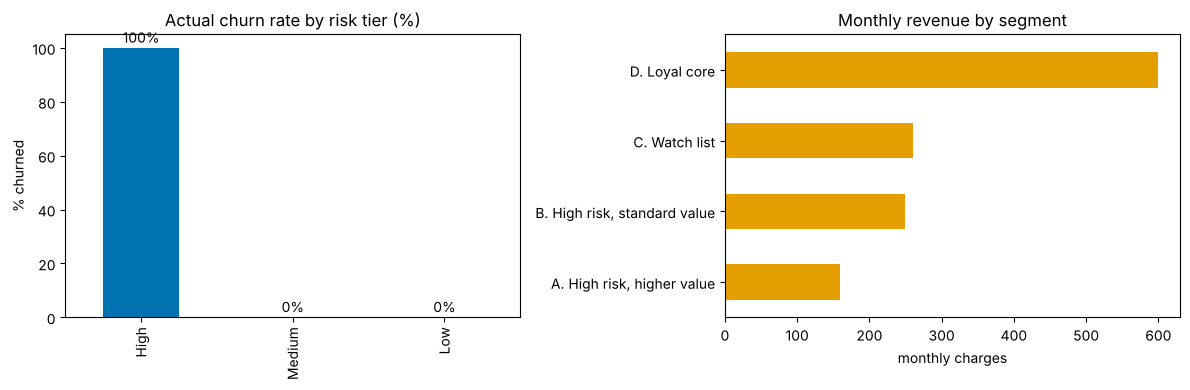

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
order = ["High", "Medium", "Low"]
rate = df.groupby("risk_tier").churned.mean().reindex(order) * 100
rate.plot.bar(ax=ax[0], color="#0072B2"); ax[0].set_title("Actual churn rate by risk tier (%)")
ax[0].set_ylabel("% churned"); ax[0].set_xlabel("")
for i, v in enumerate(rate): ax[0].text(i, v + 2, f"{v:.0f}%", ha="center")
seg.monthly_revenue.plot.barh(ax=ax[1], color="#E69F00"); ax[1].set_title("Monthly revenue by segment")
ax[1].set_xlabel("monthly charges"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

## 5. Recommendations (hypotheses to test, not proven actions)

| Segment | Customers | Suggested retention action | How to check it worked |
|---|---|---|---|
| **A. High risk, higher value** | 2 | Account-manager call within a week, plus an offer to move to a 12-month contract with a small loyalty discount | Compare 90-day churn of contacted vs not-contacted customers |
| **B. High risk, standard value** | 5 | Proactive onboarding and support follow-up during the first 90 days; resolve repeat tickets before offering discounts | Ticket count and 90-day churn |
| **C. Watch list** | 4 | Renewal reminder with a loyalty offer 60 days before the One Year contract ends | Renewal rate |
| **D. Loyal core** | 4 | No discounts. Light-touch nurture: referral invite, product updates | Keep churn near zero |

The full reasoning is in `recommendation_memo.md`.

In [7]:
df.to_csv("scored_customers.csv", index=False)
seg.reset_index().to_csv("segment_table.csv", index=False)
print("Saved scored_customers.csv and segment_table.csv")

Saved scored_customers.csv and segment_table.csv
